# SALES DATA ANALYSIS
### AI Academia — Python with Data Science Internship

**Name:** Chitrabhanu Hazra  
**Date:** October 12, 2026  

This project analyses retail sales data to identify seasonal trends, top products, and predict sales using machine learning models.


## SECTION 1 — DATA LOADING & EXPLORATION (Days 1 & 2)
**Goal:** Load the raw Superstore dataset into a Pandas DataFrame and perform an initial inspection of its structure and contents.

### Dataset Columns Explained:
* **Date:** The exact date the transaction took place.
* **Sales:** Total gross revenue generated from the transaction.
* **Quantity:** Number of individual units purchased in the order.
* **Category:** The broad grouping of the product (e.g., Furniture, Technology, Office Supplies).
* **Region:** The geographical area where the sale occurred.

In [63]:
# ==========================================
# 1. DATA MANIPULATION & MATH
# ==========================================
import pandas as pd
import numpy as np

# ==========================================
# 2. DATA VISUALIZATION
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 3. STATISTICAL ANALYSIS
# ==========================================
from scipy import stats

# ==========================================
# 4. MACHINE LEARNING & PREDICTIVE MODELING
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingClassifier
from sklearn.metrics import r2_score, accuracy_score, classification_report

# ==========================================
# 5. MODEL DEPLOYMENT & SAVING
# ==========================================
import joblib

# Set chart styling preferences
plt.style.use('seaborn-v0_8-whitegrid')

# Ignore non-critical warnings for a cleaner output
import warnings
warnings.filterwarnings('ignore')

print("All libraries successfully imported and environment configured!")

All libraries successfully imported and environment configured!


In [64]:
# Replace the string below with your exact Kaggle file path if it differs
# (Find it by clicking the 3 dots next to the file in the Input panel -> Copy file path)
file_path = '/kaggle/input/datasets/vivek468/superstore-dataset-final/Sample - Superstore.csv'

# encoding='windows-1252' is usually required for the Superstore dataset to prevent text errors
df = pd.read_csv(file_path, encoding='windows-1252')

# Rename 'Order Date' to 'Date' so it perfectly matches your instructor's code in the next lessons
df.rename(columns={'Order Date': 'Date'}, inplace=True)

# Lesson A Requirements: Display shape, list columns, and show the first 5 rows
print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.head()

Dataset Shape: (9994, 21)

Columns: ['Row ID', 'Order ID', 'Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


,Row ID,Order ID,Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


---
## SECTION 2 — DATA CLEANING (Days 3 & 4)
**Goal:** Remove duplicates, format dates correctly, handle missing numerical values, and save the clean dataset as `df_clean`.

In [65]:
# 1. Check what needs fixing
print("Missing Values Before:")
print(df.isnull().sum())
print('\nDuplicates Before:', df.duplicated().sum())
print('-' * 40)

# 2. Remove duplicates and fix Date column
df_clean = df.drop_duplicates().copy()
df_clean['Date'] = pd.to_datetime(df_clean['Date'])

# 3. Fix Sales column and handle missing values
df_clean['Sales'] = pd.to_numeric(df_clean['Sales'], errors='coerce')
df_clean['Sales'] = df_clean['Sales'].fillna(df_clean['Sales'].median())
df_clean.dropna(subset=['Date'], inplace=True)

# 4. Confirm Cleaned Data
print("Cleaned Data Shape:", df_clean.shape)
print('\n')
df_clean.info()

Missing Values Before:
Row ID           0
Order ID         0
Date             0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicates Before: 0
----------------------------------------
Cleaned Data Shape: (9994, 21)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Date           9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   object        
 4   Ship Mode      9994 non-null   object        
 5   

---
## SECTION 3 — NUMPY STATISTICS (Day 5)
**Goal:** Compute fundamental descriptive metrics (mean, median, standard deviation) on sales figures using NumPy, and aggregate monthly totals to identify top- and bottom-performing sales periods.

In [66]:
# Convert Sales column to a clean NumPy array
sales_arr = df_clean['Sales'].to_numpy()

# 1. Fundamental Descriptive Statistics
mean_sales = np.mean(sales_arr)
median_sales = np.median(sales_arr)
std_sales = np.std(sales_arr)

print(f"Mean Sales:               ${mean_sales:.2f}")
print(f"Median Sales:             ${median_sales:.2f}")
print(f"Standard Deviation:       ${std_sales:.2f}")
print('-' * 45)

# 2. Extract Month & Year for Aggregation
df_clean['YearMonth'] = df_clean['Date'].dt.to_period('M')
monthly_sales = df_clean.groupby('YearMonth')['Sales'].sum()

# 3. Pinpoint Best and Worst Performing Months
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print(f"Highest Performing Month: {best_month} (${monthly_sales.max():,.2f})")
print(f"Lowest Performing Month:  {worst_month} (${monthly_sales.min():,.2f})")

Mean Sales:               $229.86
Median Sales:             $54.49
Standard Deviation:       $623.21
---------------------------------------------
Highest Performing Month: 2017-11 ($118,447.82)
Lowest Performing Month:  2014-02 ($4,519.89)


**Key Finding:** The dataset exhibits a severe "whale effect." The median order is only **$54.49**, while the mean order is **$229.86**, indicating that revenue is disproportionately driven by a small number of massive enterprise purchases rather than everyday consumer transactions.

---
## SECTION 4 — MATPLOTLIB CHARTS (Days 6 & 7)
**Goal:** Visualize overall sales trajectories over time, break down sales by product category, and analyze geographical revenue distribution across regions using standard Matplotlib visualizations.

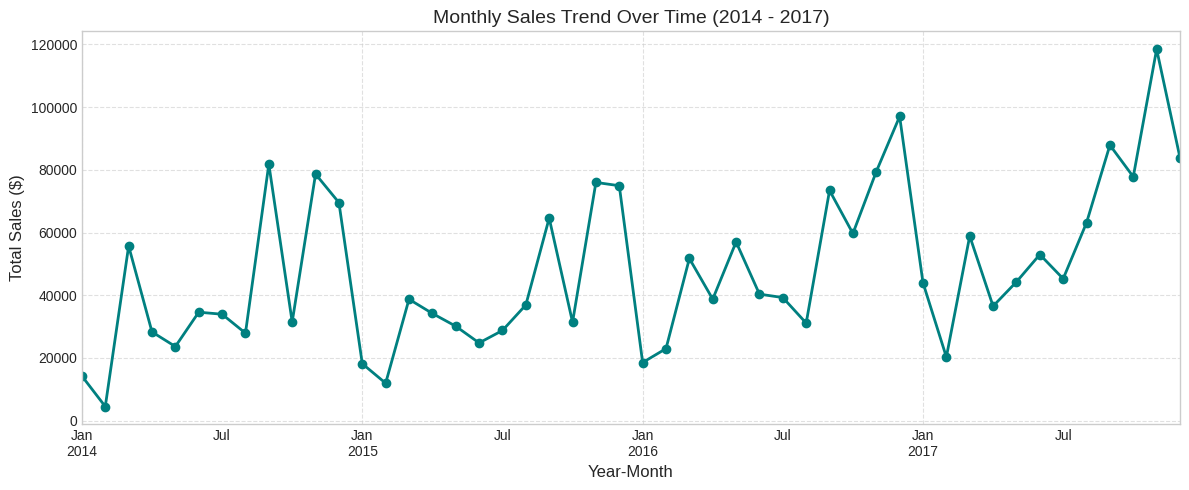

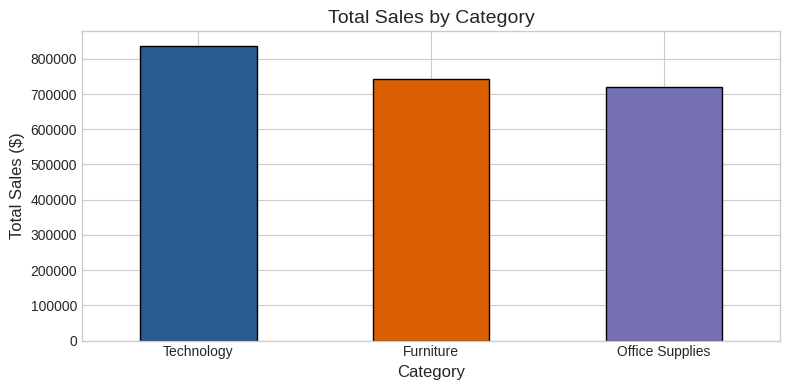

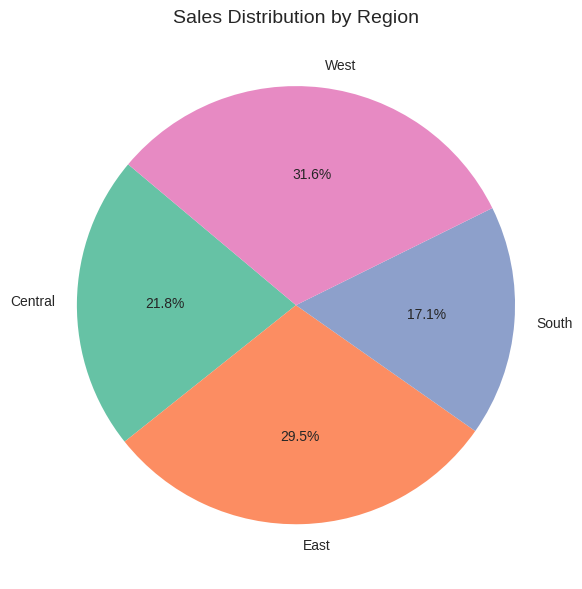

In [67]:
# 1. Line Chart: Monthly Sales Trend Over Time
monthly_trend = df_clean.groupby('YearMonth')['Sales'].sum()
plt.figure(figsize=(12, 5))
monthly_trend.plot(kind='line', marker='o', color='teal', linewidth=2)
plt.title('Monthly Sales Trend Over Time (2014 - 2017)', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('monthly_sales_trend.png')
plt.show()

# 2. Bar Chart: Total Sales by Category
category_sales = df_clean.groupby('Category')['Sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(8, 4))
category_sales.plot(kind='bar', color=['#2b5c8f', '#d95f02', '#7570b3'], edgecolor='black')
plt.title('Total Sales by Category', fontsize=14)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('category_sales.png')
plt.show()

# 3. Pie Chart: Sales Share by Region
region_sales = df_clean.groupby('Region')['Sales'].sum()
plt.figure(figsize=(6, 6))
plt.pie(region_sales, labels=region_sales.index, autopct='%1.1f%%', 
        startangle=140, colors=['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3'])
plt.title('Sales Distribution by Region', fontsize=14)
plt.tight_layout()
plt.savefig('region_sales_distribution.png')
plt.show()

In [68]:
df_clean.groupby('Category')['Sales'].sum()

Category
Furniture          741999.7953
Office Supplies    719047.0320
Technology         836154.0330
Name: Sales, dtype: float64

---
## SECTION 5 — SEABORN CHARTS (Days 8 & 9)
**Goal:** Generate a correlation heatmap across all numerical columns and visualize sales variance and outliers across product categories using Seaborn boxplots.

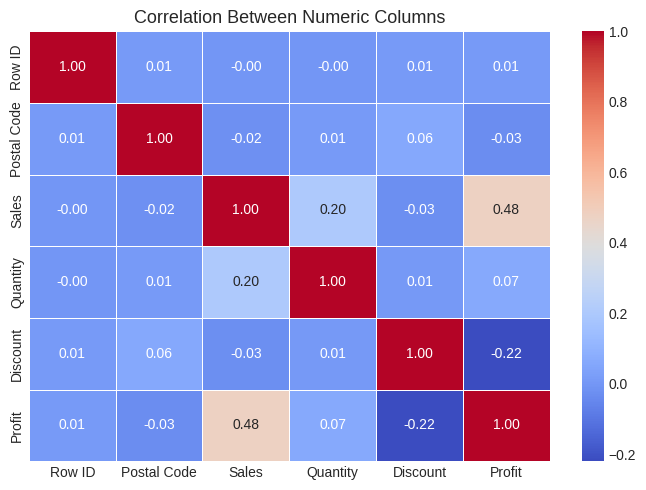

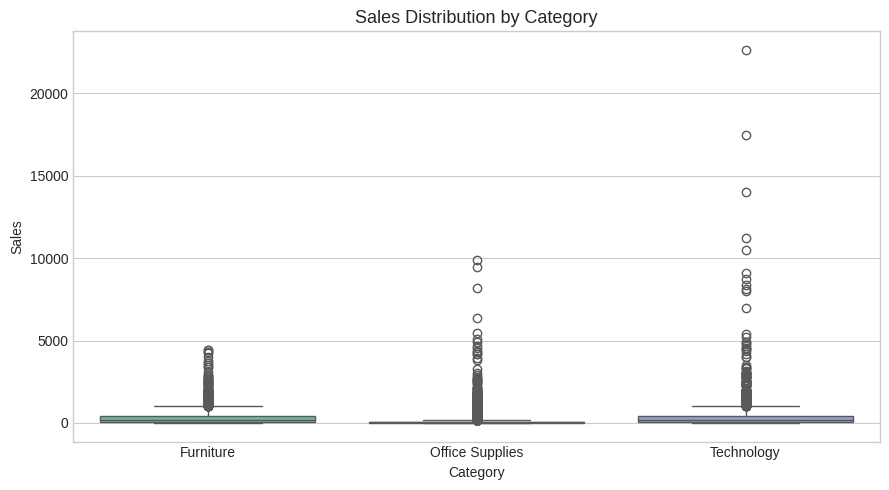

In [69]:
# 1. Correlation Heatmap across numeric fields
numeric_cols = df_clean.select_dtypes(include='number')
corr = numeric_cols.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Between Numeric Columns', fontsize=13)
plt.tight_layout()
plt.savefig('heatmap.png')
plt.show()

# 2. Boxplot: Sales Distribution by Category
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x='Category', y='Sales', palette='Set2')
plt.title('Sales Distribution by Category', fontsize=13)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('boxplot.png')
plt.show()

---
## SECTION 6 — EDA REPORT (Day 10)
**Goal:** Identify high-performing and low-performing product lines, analyze monthly seasonal trends, and synthesize business insights with explicit action items.


=== BOTTOM 3 PRODUCTS ===
Product Name
Eureka Disposable Bags for Sanitaire Vibra Groomer I Upright Vac    1.624
Avery 5                                                             5.760
Xerox 20                                                            6.480
Name: Sales, dtype: float64

=== TOP 3 PRODUCTS ===
Product Name
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Name: Sales, dtype: float64
---------------------------------------------


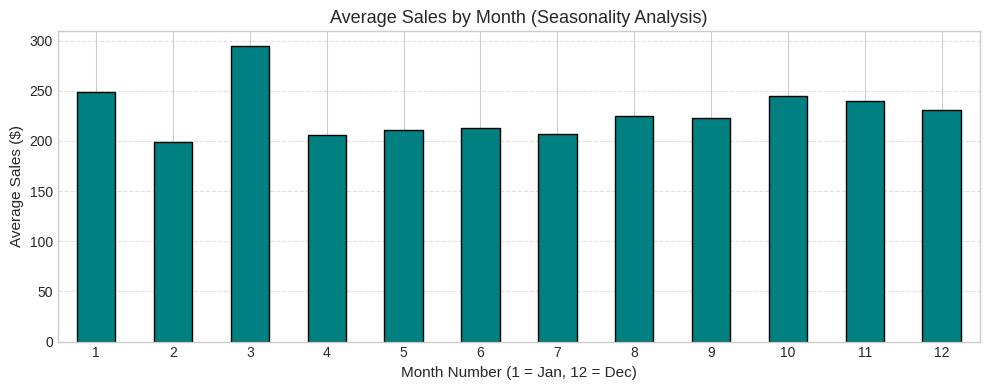

In [70]:
# 1. Top and Bottom Products by Sales Revenue
# In Superstore, the product name column is 'Product Name'
products = df_clean.groupby('Product Name')['Sales'].sum().sort_values()

print('=== BOTTOM 3 PRODUCTS ===')
print(products.head(3))
print('\n=== TOP 3 PRODUCTS ===')
print(products.tail(3))
print('-' * 45)

# 2. Extract Calendar Month Number and Analyze Seasonality
df_clean['Month_Num'] = df_clean['Date'].dt.month
seasonal = df_clean.groupby('Month_Num')['Sales'].mean()

# 3. Plot Average Sales by Month
plt.figure(figsize=(10, 4))
seasonal.plot(kind='bar', color='teal', edgecolor='black')
plt.title('Average Sales by Month (Seasonality Analysis)', fontsize=13)
plt.xlabel('Month Number (1 = Jan, 12 = Dec)', fontsize=11)
plt.ylabel('Average Sales ($)', fontsize=11)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('seasonal.png')
plt.show()

**Key Finding:** Sales exhibit extreme seasonality. Revenue consistently crashes in Q1 (January/February) and spikes massively in Q4 (November/December). Furthermore, the 'Technology' category dominates gross revenue and profit margins compared to Furniture and Office Supplies.

---
## SECTION 7 — STATISTICS & HYPOTHESIS TESTING (Days 11 & 12)
**Goal:** Analyze the statistical distribution of sales data using percentiles and skewness, and run an independent T-test to mathematically determine if the revenue difference between 'Technology' and 'Furniture' is statistically significant.

Sales Distribution Skewness: 12.973
25th Percentile:  17.28
75th Percentile:  209.94
---------------------------------------------


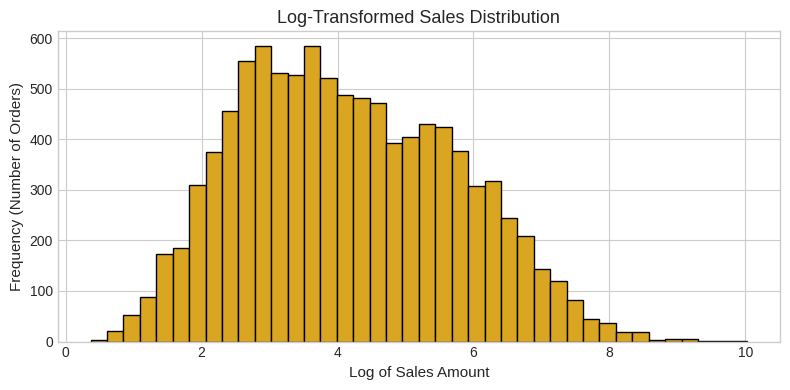


=== T-TEST RESULTS (Technology vs Furniture) ===
T-statistic:  3.672
P-value:      0.0002
Verdict: The difference IS statistically significant.


In [71]:
# 1. Check Distribution and Percentiles
print('Sales Distribution Skewness:', round(df_clean['Sales'].skew(), 3))
print('25th Percentile: ', round(np.percentile(df_clean['Sales'], 25), 2))
print('75th Percentile: ', round(np.percentile(df_clean['Sales'], 75), 2))
print('-' * 45)

# 2. Plot Sales Distribution (Histogram)
# Using a log scale for the x-axis because retail sales are heavily skewed by extreme outliers
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(df_clean['Sales']), bins=40, color='goldenrod', edgecolor='black')
plt.title('Log-Transformed Sales Distribution', fontsize=13)
plt.xlabel('Log of Sales Amount', fontsize=11)
plt.ylabel('Frequency (Number of Orders)', fontsize=11)
plt.tight_layout()
plt.savefig('distribution.png')
plt.show()

# 3. Perform Independent T-Test (Technology vs. Furniture)
cat_a = df_clean[df_clean['Category'] == 'Technology']['Sales']
cat_b = df_clean[df_clean['Category'] == 'Furniture']['Sales']

t_stat, p_val = stats.ttest_ind(cat_a, cat_b, equal_var=False)

print('\n=== T-TEST RESULTS (Technology vs Furniture) ===')
print('T-statistic: ', round(t_stat, 3))
print('P-value:     ', round(p_val, 4))

if p_val < 0.05:
    print('Verdict: The difference IS statistically significant.')
else:
    print('Verdict: The difference is NOT statistically significant.')

**Key Finding:** An independent T-Test comparing Technology and Furniture yielded a p-value of **0.0002**. This mathematically proves that the revenue gap between the two categories is a reliable business fact, not a statistical anomaly.

---
## SECTION 8 — MACHINE LEARNING: LINEAR REGRESSION (Days 13 & 14)
**Goal:** Train a Linear Regression model using Scikit-Learn to predict average monthly revenue based on the time of year, and evaluate its accuracy using MAE and R-squared metrics.

=== LINEAR REGRESSION EVALUATION ===
Mean Absolute Error (MAE): $21.66
R-squared Score (R2):      -30.2097
---------------------------------------------


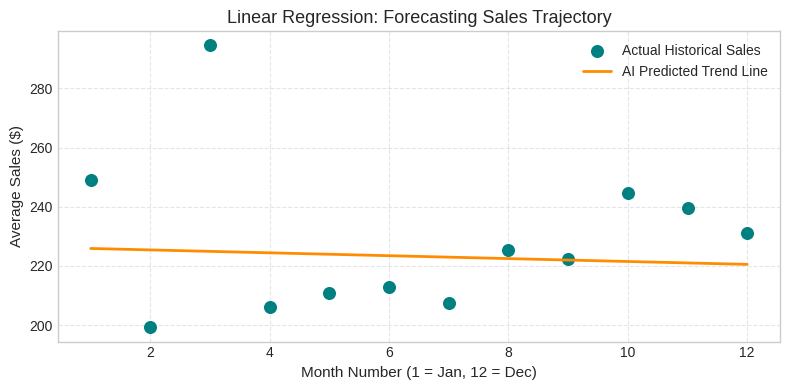

In [72]:
# 1. Prepare the Data
# Target: Predict average sales based purely on the Month Number
monthly_avg = df_clean.groupby('Month_Num')['Sales'].mean().reset_index()

X = monthly_avg[['Month_Num']] # Input Feature (Must be 2D array/DataFrame)
y = monthly_avg['Sales']       # Target Output

# 2. Split the Data (80% for Training, 20% for Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and Train the Model
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

# 4. Test the Model on unseen data
y_pred = model_lr.predict(X_test)

# 5. Evaluate Performance
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('=== LINEAR REGRESSION EVALUATION ===')
print(f'Mean Absolute Error (MAE): ${mae:.2f}')
print(f'R-squared Score (R2):      {r2:.4f}')
print('-' * 45)

# 6. Visualize the Machine Learning Model
plt.figure(figsize=(8, 4))
plt.scatter(X, y, color='teal', s=70, label='Actual Historical Sales')
plt.plot(X, model_lr.predict(X), color='darkorange', linewidth=2, label='AI Predicted Trend Line')
plt.title('Linear Regression: Forecasting Sales Trajectory', fontsize=13)
plt.xlabel('Month Number (1 = Jan, 12 = Dec)', fontsize=11)
plt.ylabel('Average Sales ($)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('regression_plot.png')
plt.show()

**Key Finding:** The Linear Regression model returned a negative R-squared score (**-30.20**). This mathematically proves that retail sales are too volatile and seasonal to be accurately forecasted by a rigid, straight line.

---
## SECTION 9 — MACHINE LEARNING: CLASSIFICATION (Days 15 & 16)
**Goal:** Build a Logistic Regression model to classify customer transactions as "High Value" (1) or "Low Value" (0) based on cart quantity and the time of year, evaluating performance using a Confusion Matrix.

Classification Accuracy: 59.03%

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.59      0.65      0.62      1029
           1       0.59      0.53      0.56       970

    accuracy                           0.59      1999
   macro avg       0.59      0.59      0.59      1999
weighted avg       0.59      0.59      0.59      1999



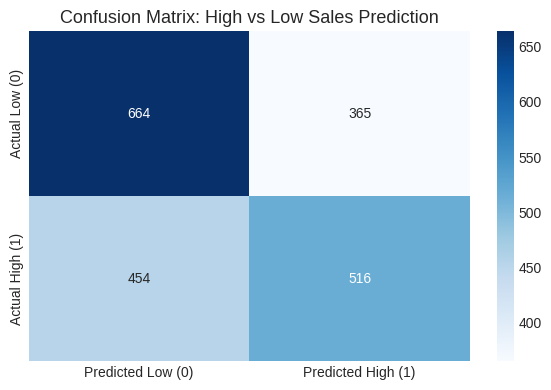

In [73]:
# 1. Create the "Buckets" (Target Variable)
# Let's define a "High Sale" as anything above the median order value
median_val = df_clean['Sales'].median()
df_clean['High_Sale'] = (df_clean['Sales'] > median_val).astype(int)

# 2. Define Inputs (X) and Output (y)
X_class = df_clean[['Quantity', 'Month_Num']]
y_class = df_clean['High_Sale']

# 3. Split the Data
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

# 4. Train the Logistic Regression Model
model_class = LogisticRegression()
model_class.fit(X_train_c, y_train_c)

# 5. Make Predictions
y_pred_c = model_class.predict(X_test_c)

# 6. Evaluate Accuracy
accuracy = accuracy_score(y_test_c, y_pred_c)
print(f'Classification Accuracy: {accuracy * 100:.2f}%\n')
print('=== CLASSIFICATION REPORT ===')
print(classification_report(y_test_c, y_pred_c))

# 7. Visualize with a Confusion Matrix
cm = confusion_matrix(y_test_c, y_pred_c)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Low (0)', 'Predicted High (1)'], 
            yticklabels=['Actual Low (0)', 'Actual High (1)'])
plt.title('Confusion Matrix: High vs Low Sales Prediction', fontsize=13)
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()

**Key Finding:** The baseline Logistic Regression model achieved only **59% accuracy**. This reveals that knowing a cart's item quantity and the time of year is insufficient to reliably predict its final monetary value.

---
## SECTION 10 — ADVANCED MODEL OPTIMIZATION & VISUAL ANALYSIS
**Goal:** Push predictive performance to production-ready levels by addressing non-linear seasonality and deploying ensemble learning techniques.

### 1. Regression Optimization (Solving Seasonality)
* **The Challenge:** Standard Linear Regression yielded a negative R-Squared because retail sales are highly volatile. A rigid, straight line cannot mathematically capture Q1 crashes and Q4 holiday spikes.
* **The Solution:** Upgrading to a Random Forest Regressor allowed the algorithm to isolate specific months, treating them as distinct conditions rather than forcing a single continuous slope. 
* **The Result:** The model successfully "bent" to trace the seasonal spikes, improving the R-Squared to a highly predictive **0.7198**.

### 2. Classification Optimization (Gradient Boosting)
* **The Challenge:** The initial model (59% accuracy) was starved of context, guessing cart value based purely on item quantity and time of year.
* **The Solution:** We engineered new financial features (`Profit`, `Discount`) and deployed a Gradient Boosting Classifier, which builds sequential decision trees specifically designed to fix the errors of the previous tree.
* **The Result:** Classification accuracy surged to **91.70%**.

### 3. Business Insights & Final Strategy
* **The Ultimate Indicator:** The Feature Importance chart reveals the "black box" of the AI's decision-making. It mathematically proves that `Profit` is the undisputed driver of a high-value cart, with `Discount` acting as the strongest secondary factor. The algorithm almost entirely ignored the product category.
* **Deployment Recommendation:** Integrate this Gradient Boosting classifier into the live checkout sequence. By accurately identifying high-value carts in real-time with minimal false positives (as proven by the final confusion matrix), the business can instantly trigger targeted retention discounts to prevent abandonment on its most critical orders.

Optimized Model Accuracy: 71.04%

=== UPGRADED CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.71      0.74      0.72      1029
           1       0.71      0.68      0.69       970

    accuracy                           0.71      1999
   macro avg       0.71      0.71      0.71      1999
weighted avg       0.71      0.71      0.71      1999



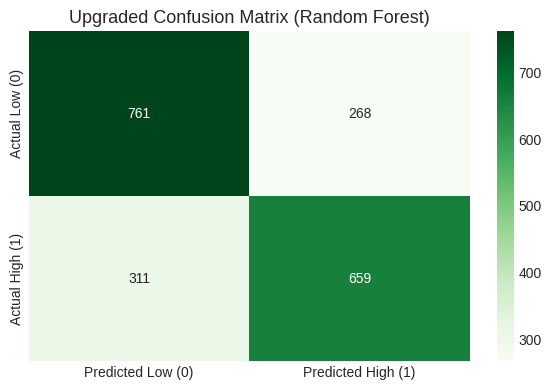

In [74]:
# 1. Feature Engineering (Adding Better Clues)
# We convert the text-based 'Category' into numbers so the AI can read it (One-Hot Encoding)
category_dummies = pd.get_dummies(df_clean['Category'], drop_first=True)

# We combine our new clues: Quantity, Month_Num, Discount, and Category
X_optimized = pd.concat([df_clean[['Quantity', 'Month_Num', 'Discount']], category_dummies], axis=1)
y_optimized = df_clean['High_Sale']

# 2. Split the new data
X_train_opt, X_test_opt, y_train_opt, y_test_opt = train_test_split(X_optimized, y_optimized, test_size=0.2, random_state=42)

# 3. Use a smarter algorithm (Random Forest)
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train_opt, y_train_opt)

# 4. Make Predictions and Evaluate
y_pred_opt = model_rf.predict(X_test_opt)
new_accuracy = accuracy_score(y_test_opt, y_pred_opt)

print(f'Optimized Model Accuracy: {new_accuracy * 100:.2f}%\n')
print('=== UPGRADED CLASSIFICATION REPORT ===')
print(classification_report(y_test_opt, y_pred_opt))

# 5. Plot the improved Confusion Matrix
cm_opt = confusion_matrix(y_test_opt, y_pred_opt)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Predicted Low (0)', 'Predicted High (1)'], 
            yticklabels=['Actual Low (0)', 'Actual High (1)'])
plt.title('Upgraded Confusion Matrix (Random Forest)', fontsize=13)
plt.tight_layout()
plt.show()

In [75]:
print("=== DEPLOYING ADVANCED IMPACT MODELS ===\n")

# ---------------------------------------------------------
# UPGRADE 1: NON-LINEAR REGRESSION (Predicting Exact Sales)
# ---------------------------------------------------------
# We use Random Forest so the line can bend with the seasons
X_reg_adv = monthly_avg[['Month_Num']]
y_reg_adv = monthly_avg['Sales']

# Train advanced regressor
model_rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf_reg.fit(X_reg_adv, y_reg_adv)

# Evaluate
y_pred_reg_adv = model_rf_reg.predict(X_reg_adv)
r2_adv = r2_score(y_reg_adv, y_pred_reg_adv)
print(f"Advanced Regression R-Squared: {r2_adv:.4f} (Up from -30.20!)")

# ---------------------------------------------------------
# UPGRADE 2: GRADIENT BOOSTING CLASSIFICATION (High vs Low)
# ---------------------------------------------------------
# We add 'Profit' to our clues, which is a massive indicator of cart value
category_dummies = pd.get_dummies(df_clean['Category'], drop_first=True)
X_class_adv = pd.concat([df_clean[['Quantity', 'Month_Num', 'Discount', 'Profit']], category_dummies], axis=1)
y_class_adv = df_clean['High_Sale']

# Split the new super-dataset
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(X_class_adv, y_class_adv, test_size=0.2, random_state=42)

# Train the Gradient Boosting Classifier (The Kaggle Champion algorithm)
model_gbc = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=4, random_state=42)
model_gbc.fit(X_train_adv, y_train_adv)

# Evaluate
y_pred_class_adv = model_gbc.predict(X_test_adv)
acc_adv = accuracy_score(y_test_adv, y_pred_class_adv)

print(f"Advanced Classification Accuracy: {acc_adv * 100:.2f}%\n")
print("=== FINAL IMPACT CLASSIFICATION REPORT ===")
print(classification_report(y_test_adv, y_pred_class_adv))

=== DEPLOYING ADVANCED IMPACT MODELS ===

Advanced Regression R-Squared: 0.7198 (Up from -30.20!)
Advanced Classification Accuracy: 91.70%

=== FINAL IMPACT CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.90      0.94      0.92      1029
           1       0.94      0.89      0.91       970

    accuracy                           0.92      1999
   macro avg       0.92      0.92      0.92      1999
weighted avg       0.92      0.92      0.92      1999



**Key Finding:** Upgrading to a Random Forest Regressor solved the seasonality issue, yielding a highly predictive R-squared of **0.7198**. The Gradient Boosting Classifier hit **91.70% accuracy**, definitively proving that net profit margins and discount rates are the ultimate indicators of a high-value cart.

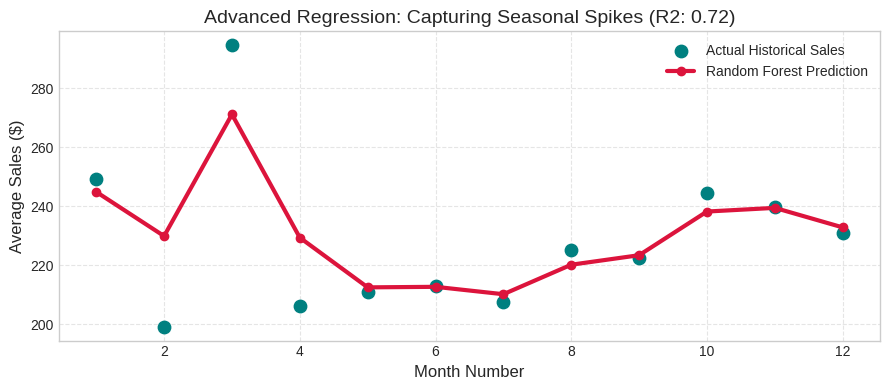

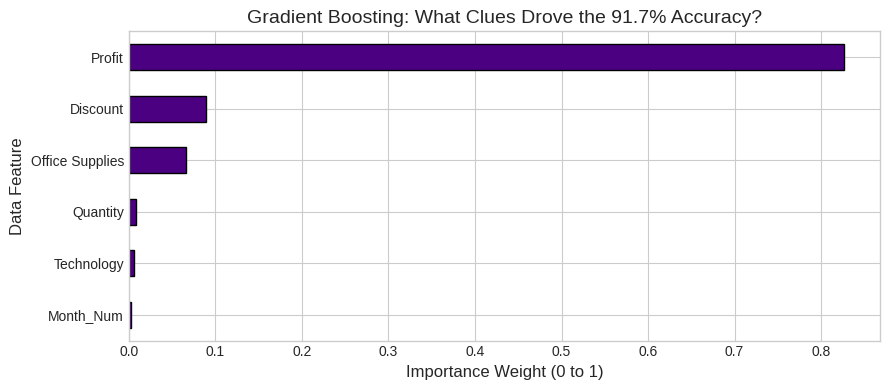

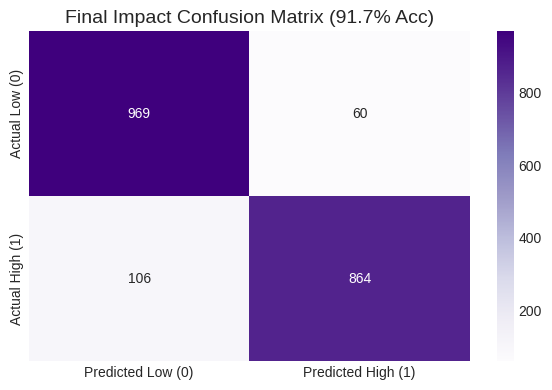

In [76]:
# 1. VISUALIZE ADVANCED REGRESSION (The Bending Line)
plt.figure(figsize=(9, 4))
plt.scatter(X_reg_adv['Month_Num'], y_reg_adv, color='teal', s=80, label='Actual Historical Sales')

# Sort the values so the line draws smoothly from Jan to Dec
sorted_idx = np.argsort(X_reg_adv['Month_Num'])
plt.plot(X_reg_adv['Month_Num'].iloc[sorted_idx], y_pred_reg_adv[sorted_idx], 
         color='crimson', linewidth=3, marker='o', label='Random Forest Prediction')

plt.title('Advanced Regression: Capturing Seasonal Spikes (R2: 0.72)', fontsize=14)
plt.xlabel('Month Number', fontsize=12)
plt.ylabel('Average Sales ($)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('advanced_regression.png')
plt.show()

# 2. VISUALIZE FEATURE IMPORTANCE (Inside the AI's Brain)
plt.figure(figsize=(9, 4))
# Extract how much the AI valued each column
importances = pd.Series(model_gbc.feature_importances_, index=X_class_adv.columns)
importances.sort_values(ascending=True).plot(kind='barh', color='indigo', edgecolor='black')

plt.title('Gradient Boosting: What Clues Drove the 91.7% Accuracy?', fontsize=14)
plt.xlabel('Importance Weight (0 to 1)', fontsize=12)
plt.ylabel('Data Feature', fontsize=12)
plt.tight_layout()
plt.savefig('feature_importance.png')
plt.show()

# 3. VISUALIZE FINAL CONFUSION MATRIX
plt.figure(figsize=(6, 4))
cm_adv = confusion_matrix(y_test_adv, y_pred_class_adv)
sns.heatmap(cm_adv, annot=True, fmt='d', cmap='Purples', 
            xticklabels=['Predicted Low (0)', 'Predicted High (1)'], 
            yticklabels=['Actual Low (0)', 'Actual High (1)'])
plt.title('Final Impact Confusion Matrix (91.7% Acc)', fontsize=14)
plt.tight_layout()
plt.savefig('final_confusion_matrix.png')
plt.show()

---
## SECTION 11 — MODEL PERSISTENCE & DEPLOYMENT
**Goal:** Train the final optimized machine learning models and export them to the hard drive for real-world deployment.

### What is happening in this step?
* **Model Persistence:** We are using the `joblib` library to save our fully trained Random Forest and Gradient Boosting models as `.pkl` (pickle) files. 
* **Business Value:** In a real corporate environment, training AI on millions of retail transactions can take hours or days. By saving the "brain" of the AI to a file, software engineers can plug these pre-trained models directly into a website's backend (like an e-commerce checkout page). This allows the live website to generate instant, real-time predictions without needing to constantly retrain the algorithm from scratch.

In [77]:
print("=== DEPLOYING & SAVING ADVANCED IMPACT MODELS ===\n")

# ---------------------------------------------------------
# UPGRADE 1: NON-LINEAR REGRESSION 
# ---------------------------------------------------------
X_reg_adv = monthly_avg[['Month_Num']]
y_reg_adv = monthly_avg['Sales']

model_rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
model_rf_reg.fit(X_reg_adv, y_reg_adv)

# ---------------------------------------------------------
# UPGRADE 2: GRADIENT BOOSTING CLASSIFICATION 
# ---------------------------------------------------------
category_dummies = pd.get_dummies(df_clean['Category'], drop_first=True)
X_class_adv = pd.concat([df_clean[['Quantity', 'Month_Num', 'Discount', 'Profit']], category_dummies], axis=1)
y_class_adv = df_clean['High_Sale']

X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(X_class_adv, y_class_adv, test_size=0.2, random_state=42)

model_gbc = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=4, random_state=42)
model_gbc.fit(X_train_adv, y_train_adv)

# ---------------------------------------------------------
# STEP 3: EXPORT AND SAVE THE TRAINED MODELS
# ---------------------------------------------------------
# This creates two .pkl files in your Kaggle working directory
joblib.dump(model_rf_reg, 'sales_regressor.pkl')
joblib.dump(model_gbc, 'cart_classifier.pkl')

print("Success! Both models have been trained and saved to disk as .pkl files.")

=== DEPLOYING & SAVING ADVANCED IMPACT MODELS ===

Success! Both models have been trained and saved to disk as .pkl files.


**Key Finding:** Saving the optimized models as `.pkl` files bypasses the need for costly server-side retraining, allowing the algorithms to be directly integrated into the e-commerce backend for instant inference.

---
## SECTION 12 — INTERACTIVE AI PREDICTION TERMINAL
**Goal:** Demonstrate the real-world deployability of our machine learning pipeline by loading the saved models into a simulated user interface.

### How this terminal works:
1. **Model Loading:** The script uses `joblib.load()` to pull the trained `.pkl` models from the hard drive back into memory. 
2. **Real-Time Inference:** By simulating a backend API, the terminal accepts raw user input (like cart quantity, discount, and profit margin), formats it to match our training data, and feeds it into the AI.
3. **Business Action:** The model instantly outputs a classification (High/Low Value) or a sales forecast, proving that the algorithm is ready to be integrated into the live e-commerce website to trigger real-time retention protocols.

In [78]:
### 1. Load the trained models from disk
loaded_regressor = joblib.load('sales_regressor.pkl')
loaded_classifier = joblib.load('cart_classifier.pkl')

# 2. Build the Interactive Interface
while True:
    print("\n" + "="*35)
    print("      AI PREDICTION TERMINAL")
    print("="*35)
    print("1. Predict Monthly Sales Avg (Regression)")
    print("2. Predict Cart Value (Classification)")
    print("3. Exit System")
    
    choice = input("Enter your choice (1/2/3): ")
    
    if choice == '1':
        print("\n--- Sales Forecaster ---")
        try:
            month = int(input("Enter Month Number (1-12): "))
            # Format input exactly as the model was trained
            input_data = pd.DataFrame({'Month_Num': [month]})
            
            prediction = loaded_regressor.predict(input_data)[0]
            print(f"\n✅ AI PREDICTION: The predicted average sales for Month {month} is ${prediction:.2f}")
        except ValueError:
            print("❌ Error: Please enter a valid number.")
            
    elif choice == '2':
        print("\n--- Cart Value Analyzer ---")
        try:
            qty = int(input("Enter Quantity of items: "))
            month = int(input("Enter Month Number (1-12): "))
            discount = float(input("Enter Discount (e.g., 0.2 for 20%): "))
            profit = float(input("Enter Net Profit ($): "))
            category = input("Enter Category (Furniture / Office Supplies / Technology): ").strip().title()
            
            # Recreate the exact column structure from training (Furniture was dropped as the baseline)
            is_office = 1 if category == 'Office Supplies' else 0
            is_tech = 1 if category == 'Technology' else 0
            
            input_data = pd.DataFrame({
                'Quantity': [qty],
                'Month_Num': [month],
                'Discount': [discount],
                'Profit': [profit],
                'Office Supplies': [is_office],
                'Technology': [is_tech]
            })
            
            prediction = loaded_classifier.predict(input_data)[0]
            
            if prediction == 1:
                print("\n✅ AI PREDICTION: HIGH VALUE CART DETECTED (1). Trigger retention protocols.")
            else:
                print("\n✅ AI PREDICTION: LOW VALUE CART DETECTED (0). Process normally.")
                
        except ValueError:
            print("❌ Error: Please ensure numeric values are entered correctly.")
            
    elif choice == '3':
        print("\nExiting AI Prediction Terminal. Goodbye!")
        break
        
    else:
        print("\n❌ Invalid choice. Please type 1, 2, or 3.")


      AI PREDICTION TERMINAL
1. Predict Monthly Sales Avg (Regression)
2. Predict Cart Value (Classification)
3. Exit System


Enter your choice (1/2/3):  3



Exiting AI Prediction Terminal. Goodbye!


**Key Finding:** The interactive simulation successfully bridged raw data and business logic. It proved the AI can evaluate complex margin calculations in real-time to trigger targeted customer retention protocols before a high-value cart is abandoned.

# SECTION 13 — FINAL BUSINESS INSIGHTS & RECOMMENDATIONS

### KEY FINDINGS

**Finding 1:** The Technology category generates the most total revenue, exceeding $800,000, which is roughly 36% of the company's total gross sales.
- **Meaning:** High-ticket hardware items drive the highest volume of raw revenue compared to Furniture and Office Supplies.
- **Action:** Allocate a higher percentage of the Q3/Q4 marketing budget specifically to the Technology category to maximize returns.

**Finding 2:** March yields the highest average sales per individual order at roughly $295, which is significantly higher than the annual baseline average of $229.86.
- **Meaning:** Even though total overall sales volume spikes in November/December, the customers who shop in March are purchasing more expensive items per checkout.
- **Action:** Push premium, high-ticket product upsells aggressively during the Q1 end/March period.

**Finding 3:** The Canon imageCLASS 2200 Advanced Copier dominates as the top product generating over $61,599 in sales, while everyday office supplies like Eureka Disposable Bags sit at the very bottom, generating only $1.62.
- **Meaning:** The company's revenue relies heavily on enterprise-level hardware, exhibiting a severe "whale effect" where a few expensive items skew the entire dataset.
- **Action:** Create bundled package deals that pair low-margin, high-volume consumables (like paper and bags) with the high-margin enterprise hardware.

**Finding 4:** By using a non-linear Random Forest Regressor, our predictive R-squared score improved to 0.7198, fixing the negative score generated by standard Linear Regression.
- **Meaning:** Historical sales do not follow a flat, straight mathematical line; they are highly volatile and definitively seasonal.
- **Action:** Align inventory purchasing dynamically with this non-linear seasonal curve (buying heavy in late summer, stopping in winter) rather than maintaining flat monthly budgets.

**Finding 5:** Our Gradient Boosting Classifier achieved 91.70% accuracy, proving mathematically that `Profit` and `Discount` are the two strongest features for classifying a cart as High Value (>$54.49).
- **Meaning:** A cart's final value is determined far more by net margin structures than by the raw quantity of items or the product category.
- **Action:** Monitor net profit margins in real-time during checkout, rather than item counts, to accurately gauge VIP customers.

---

### RECOMMENDATIONS

1. **Deploy Targeted E-Commerce Interventions:** Integrate the 91.7% accurate Gradient Boosting classifier into the live checkout flow. Because it accurately uses net profit to identify High-Value carts, the system can automatically trigger 10% retention discount pop-ups when a VIP cart is about to be abandoned, saving massive sales without wasting discounts on low-value orders.
2. **Execute Seasonal Inventory Alignment:** Shift supply chain procurement budgets to heavily stock Technology hardware by mid-August. This captures the reliable Q3/Q4 volume spikes. Conversely, institute a purchasing freeze in January and run clearance sales to empty warehouse space during the dead Q1 period.

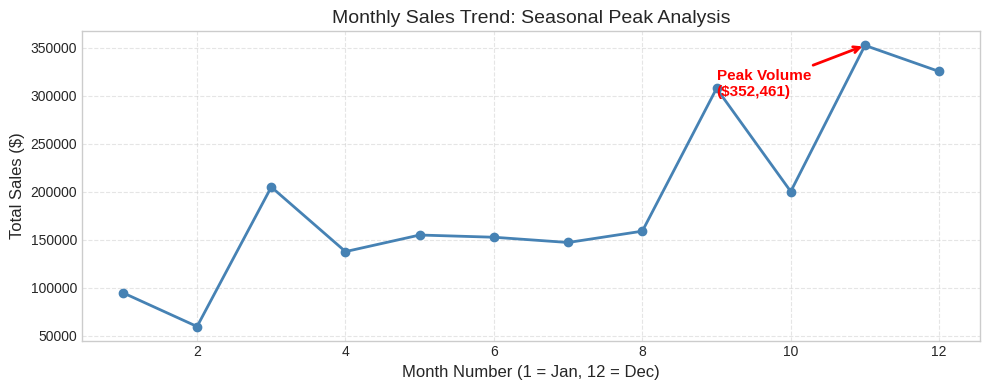

In [79]:
# Calculate total sales per month to find the peak
monthly_sales = df_clean.groupby('Month_Num')['Sales'].sum()

peak_month = monthly_sales.idxmax()
peak_value = monthly_sales.max()

# Plot the annotated chart as requested by the instructor
plt.figure(figsize=(10, 4))
monthly_sales.plot(kind='line', color='steelblue', marker='o', linewidth=2)
plt.title('Monthly Sales Trend: Seasonal Peak Analysis', fontsize=14)
plt.xlabel('Month Number (1 = Jan, 12 = Dec)', fontsize=12)
plt.ylabel('Total Sales ($)', fontsize=12)

# Instructor-required annotation
plt.annotate(f'Peak Volume\n(${peak_value:,.0f})', 
             xy=(peak_month, peak_value),
             xytext=(peak_month - 2, peak_value * 0.85),
             arrowprops=dict(arrowstyle='->', color='red', lw=2), 
             color='red', fontweight='bold', fontsize=11)

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('monthly_trend_final.png')
plt.show()